# Proyecto MA4703 Control Óptimo — Avance: Objetivo 2
## Control estocástico del modelo de Black-Scholes (problema de Merton)

* Profesor: Héctor Ramírez.
* Auxiliares: Hernán Torres, Diego Morales.
* Ayudante: Fraick Reyes.
* Integrantes: Bonnie Lagos, Javier Cruz.

**Objetivo de este avance.** Simular las trayectorias del capital con distintos tipos de controles y estimar su utilidad esperada con **Monte-Carlo**, validando todo contra la solución exacta de Merton.

Este notebook implementa exactamente lo que se presenta en el avance:

1. **Problema de Merton** (Sección 1): modelo, utilidad CRRA, controles admisibles $\mathcal A_K$ y los resultados teóricos que se usan (control óptimo, HJB).
2. **Monte-Carlo** (Secciones 2 a 5), en los tres pasos de la slide *Avances Simulación: Monte Carlo*:
   1. simulación exacta (log-Euler);
   2. estimador $\hat J_N$ con intervalo de confianza y variables antitéticas;
   3. referencia exacta $J(x;\bar\pi,\bar c)$, con $J=V(x)$ en el control de Merton.
3. **Figura de la presentación** (Sección 6), que se guarda como `mc_merton.pdf`.

Lo que la presentación declara **pendiente** (filtro de Kalman, HJB numérica, controles restringidos, horizonte finito o tiempo de parada y extensiones) no se implementa aquí; ver Sección 7.

**Referencias.** [KS] Karatzas–Shreve, *Brownian Motion and Stochastic Calculus*; [R] Ross, *Stochastic Control in Continuous Time*; [CRRA] documento teórico del proyecto, *El problema de Merton con utilidad CRRA*.

In [1]:
import Pkg; Pkg.add("Plots")   # Statistics, Random y Printf vienen incluidos en Julia
using Plots, Statistics, Random, Printf

     Project No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Manifest.toml`


## 1. Problema de Merton

**Modelo.** Con $\mu>r>0$, $\sigma>0$ y $B$ un movimiento browniano, el capital del inversionista con fracción $\Pi_t$ invertida en la acción y consumo $C_t$ es
$$
dX_t=\big[(r+\Pi_t(\mu-r))X_t-C_t\big]dt+\sigma\Pi_tX_t\,dB_t,\qquad X_0=x>0.
$$

**Utilidad CRRA.** $U(c)=\dfrac{c^{1-\eta}-1}{1-\eta}$ ($\eta\ne1$). En este avance $\eta=2$, es decir $U(c)=1-\frac1c$ y $U(0)=-\infty$. (En algunas slides se escribe $R$ en lugar de $\eta$.)

**Controles admisibles** $\mathcal A_K$ [KS, Def. 5.8.2 y 5.8.5]: con $\pi_t=\Pi_tX_t$, para todo $T>0$,
$$
\int_0^T\pi_t^2\,dt<\infty,\qquad C_t\ge0,\qquad \int_0^TC_t\,dt<\infty,\qquad X_t\ge0\ \ \forall t\in[0,T]\quad\text{c.s.}
$$

**Problema.** $V(x)=\sup_{\mathcal A_K}J(x;\Pi,C)$, con $J(x;\Pi,C)=\mathbb E_x\big[\int_0^\infty e^{-\gamma t}U(C_t)\,dt\big]$.

**Resultados teóricos que se usan** [R, Teo. 2.7.2; CRRA, Teo. 8.1]. Sea $\theta=(\mu-r)/\sigma$ y
$$
\nu=\frac1\eta\Big[\gamma-(1-\eta)\Big(r+\frac{\theta^2}{2\eta}\Big)\Big].
$$
Si $\nu>0$ (siempre si $\eta\ge1$), el control de Markov $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$, $C^*_t=\nu X^*_t$ es óptimo en $\mathcal A_K$, la riqueza $X^*$ es lognormal (nunca quiebra) y
$$
V(x)=\frac{1}{1-\eta}\Big(\nu^{-\eta}x^{1-\eta}-\frac1\gamma\Big),
$$
que es la solución de la ecuación HJB $\ \gamma V=\sup_{\Pi,\,c\ge0}\big\{U(c)+[(r+\Pi(\mu-r))x-c]V'+\tfrac12\sigma^2\Pi^2x^2V''\big\}$.

Estos valores exactos son la **referencia** contra la que se valida Monte-Carlo.

In [22]:
# parámetros del modelo (los mismos de la presentación y del reporte)
const par = (r = 0.03,      # tasa libre de riesgo
             mu = 0.08,     # retorno medio de la acción
             sigma = 0.20,  # volatilidad
             eta = 2.0,     # aversión relativa al riesgo (CRRA)
             gamma = 0.05,  # tasa de descuento
             x0 = 100.0)    # capital inicial

U(c; P=par) = (c^(1 - P.eta) - 1)/(1 - P.eta)   # utilidad CRRA (eta != 1); con eta = 2: 1 - 1/c

const theta = (par.mu - par.r)/par.sigma                                         # precio de mercado del riesgo
const Pim   = (par.mu - par.r)/(par.eta*par.sigma^2)                             # fracción óptima Pi*
const nu    = (par.gamma - (1 - par.eta)*(par.r + theta^2/(2*par.eta)))/par.eta  # tasa óptima de consumo
V(x; P=par) = (nu^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)                # función valor

@printf("theta = %.4f   Pi* = %.4f   nu = %.6f   V(x0) = %.6f\n", theta, Pim, nu, V(par.x0))

theta = 0.2500   Pi* = 0.6250   nu = 0.047813   V(x0) = 15.625614


## 2. Paso 1: simulación exacta

Simulamos estrategias **proporcionales** $\Pi_t\equiv\bar\pi$, $C_t=\bar cX_t$ (retroalimentación lineal en el estado). Tienen fracción acotada, así que son admisibles en la clase de Ross $\mathcal A_R\subseteq\mathcal A_K$, y el control de Merton es una de ellas.

**Proposición 1 (simulación exacta).** Con $\Pi\equiv\bar\pi$ y $C=\bar cX$,
$$
X_t=x\exp\Big(\big(r+\bar\pi(\mu-r)-\bar c-\tfrac12\sigma^2\bar\pi^2\big)t+\sigma\bar\pi B_t\Big)>0,
$$
así que, con $Z\sim\mathcal N(0,1)$ independiente del pasado, el esquema log-Euler
$$
X_{t+h}=X_t\,e^{\left(r+\bar\pi(\mu-r)-\bar c-\frac12\sigma^2\bar\pi^2\right)h+\sigma\bar\pi\sqrt h\,Z}
$$
**no tiene error de discretización**: da la ley exacta de $(X_{t_k})_k$ en la grilla. Además $X>0$, así que nunca hay quiebra.

*Demostración.* Por Itô, $d\big(xe^{Y_t}\big)=xe^{Y_t}\big[(r+\bar\pi(\mu-r)-\bar c)dt+\sigma\bar\pi\,dB_t\big]$ con $Y_t$ el exponente, y por unicidad fuerte esa es la solución. Como $B_{t+h}-B_t\sim\sqrt h\,Z$ es independiente de $\mathcal F_t$, el paso del esquema es exacto. $\blacksquare$

(Un esquema de Euler–Maruyama, en cambio, tiene error de discretización y puede volver negativo el capital, lo que con $\eta=2$ da utilidad $-\infty$.)

In [23]:
# Esquema exacto (Prop. 1) para la estrategia proporcional (Pi, c X).
# Z: matriz K x N de normales estándar (K pasos, N trayectorias). Devuelve X en t_k = k h, matriz (K+1) x N.
function simular_exacto(Pi, c, Z, h; P=par, x=P.x0)
    a = P.r + Pi*(P.mu - P.r) - c - 0.5*P.sigma^2*Pi^2      # deriva de log X
    logX = log(x) .+ cumsum(a*h .+ P.sigma*Pi*sqrt(h) .* Z, dims=1)
    return vcat(fill(x, 1, size(Z, 2)), exp.(logX))
end

# Distintos tipos de controles proporcionales que comparamos
controles = ["Merton (Pi*, nu)"          => (Pim, nu),
             "Solo banco (0, nu)"        => (0.0, nu),
             "Todo en acción (1, nu)"    => (1.0, nu),
             "Kelly (2Pi*, nu)"          => (2Pim, nu),
             "Consumo bajo (Pi*, nu/2)"  => (Pim, nu/2),
             "Consumo alto (Pi*, 3nu/2)" => (Pim, 1.5nu)]

6-element Vector{Pair{String, Tuple{Float64, Float64}}}:
          "Merton (Pi*, nu)" => (0.6249999999999999, 0.0478125)
        "Solo banco (0, nu)" => (0.0, 0.0478125)
    "Todo en acción (1, nu)" => (1.0, 0.0478125)
          "Kelly (2Pi*, nu)" => (1.2499999999999998, 0.0478125)
  "Consumo bajo (Pi*, nu/2)" => (0.6249999999999999, 0.02390625)
 "Consumo alto (Pi*, 3nu/2)" => (0.6249999999999999, 0.07171875)

**Trayectorias.** Usamos los **mismos escenarios** (la misma matriz $Z$) para todos los controles, así que las diferencias entre los gráficos se deben solo al control. Se grafican 20 trayectorias, la mediana con la banda 5%–95% (300 trayectorias) y la media exacta $\mathbb E[X_t]=xe^{(r+\bar\pi(\mu-r)-\bar c)t}$.

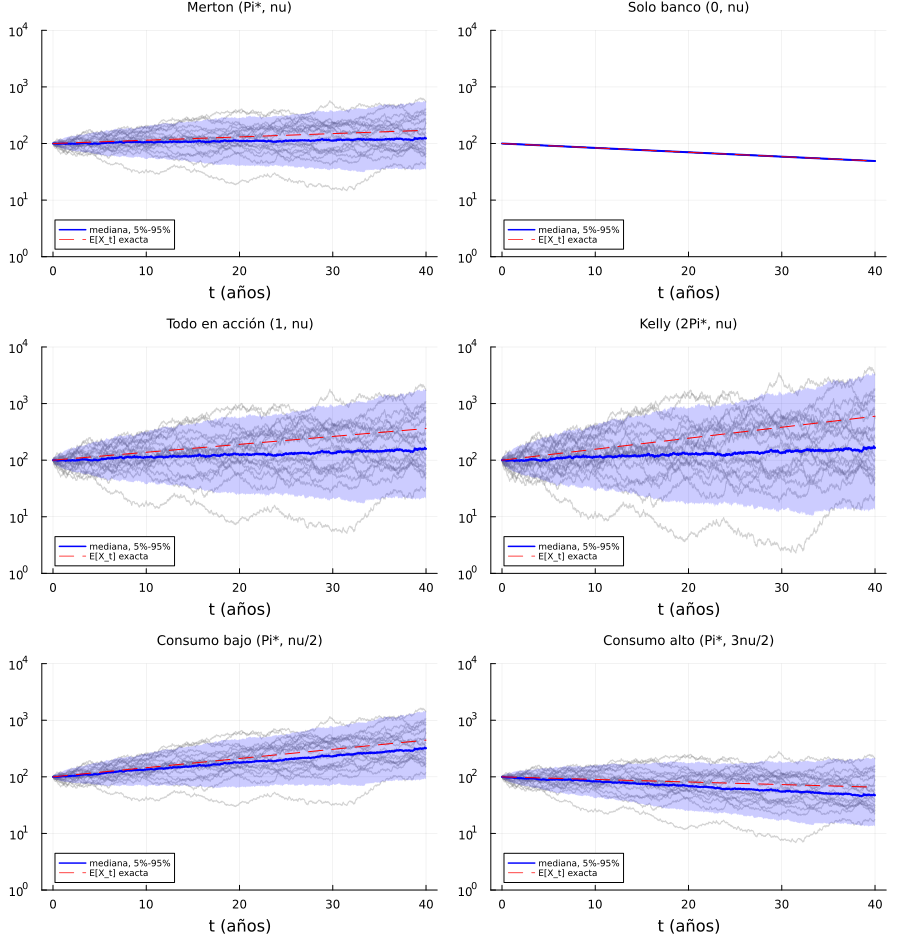

In [24]:
Random.seed!(1)
T, h, N = 40.0, 1/52, 300
K = round(Int, T/h); t = h .* (0:K)
Z = randn(K, N)   # escenarios comunes a todos los controles

figs = []
for (nombre, (Pi, c)) in controles
    X = simular_exacto(Pi, c, Z, h)
    q = [quantile(X[k, :], [0.05, 0.5, 0.95]) for k in 1:K+1]
    med = getindex.(q, 2)
    pl = plot(t, X[:, 1:20], color=:gray, alpha=0.35, primary=false, title=nombre, titlefontsize=9,
              yscale=:log10, ylims=(1, 1e4))
    plot!(pl, t, med, ribbon=(med .- getindex.(q, 1), getindex.(q, 3) .- med),
          fillalpha=0.2, color=:blue, lw=2, label="mediana, 5%-95%")
    plot!(pl, t, par.x0 .* exp.((par.r + Pi*(par.mu - par.r) - c) .* t), color=:red, ls=:dash, label="E[X_t] exacta")
    push!(figs, pl)
    @assert minimum(X) > 0   # Prop. 1: el capital nunca se anula
end
plot(figs..., layout=(3, 2), size=(900, 950), legend=:bottomleft, legendfontsize=6, xlabel="t (años)")

* **Solo banco** es determinista, $X_t=xe^{(r-\nu)t}$, y decrece a tasa $\nu-r\approx1.8\%$ anual.
* En **Merton** la media crece a tasa $r+\Pi^*(\mu-r)-\nu\approx1.3\%$ anual, y la mediana a $\approx0.6\%$.
* **Kelly** ($2\Pi^*$) tiene la mediana que más crece, pero también la mayor dispersión.
* **Consumo alto** hace caer el capital y **consumo bajo** lo acumula.

## 3. Paso 3: referencia exacta

**Proposición 2.** Sea $\eta>1$ y
$$
\kappa(\bar\pi,\bar c)=\gamma-(1-\eta)\Big(r+\bar\pi(\mu-r)-\bar c-\tfrac\eta2\sigma^2\bar\pi^2\Big).
$$
Si $\kappa>0$,
$$
J(x;\bar\pi,\bar c)=\frac{(\bar cx)^{1-\eta}}{(1-\eta)\kappa}-\frac{1}{(1-\eta)\gamma},
$$
y si $\kappa\le0$, $J=-\infty$. En $(\Pi^*,\nu)$ se tiene $\kappa=\nu$ y $J=V(x)$. El funcional truncado en $[0,T]$ es $J_T=\frac{1}{1-\eta}\Big((\bar cx)^{1-\eta}\frac{1-e^{-\kappa T}}{\kappa}-\frac{1-e^{-\gamma T}}{\gamma}\Big)$.

*Demostración.* Por la Prop. 1, $\log X_t$ es gaussiano y $e^{-\gamma t}\mathbb E[X_t^{1-\eta}]=x^{1-\eta}e^{-\kappa t}$. Como $U(\bar cX_t)=\frac{(\bar cX_t)^{1-\eta}-1}{1-\eta}$ y el término $(\bar cX_t)^{1-\eta}$ es positivo, por Tonelli $\mathbb E\int_0^\infty e^{-\gamma t}(\bar cX_t)^{1-\eta}dt=(\bar cx)^{1-\eta}/\kappa$ si $\kappa>0$ y $+\infty$ si no. Con $(\bar\pi,\bar c)=(\Pi^*,\nu)$, $\bar\pi(\mu-r)-\frac\eta2\sigma^2\bar\pi^2=\frac{\theta^2}{2\eta}$ y $\kappa=\eta\nu+(1-\eta)\nu=\nu$. $\blacksquare$

**Corolario 1.** Entre las estrategias proporcionales, $J$ es máximo en $(\Pi^*,\nu)$. En particular (con $\eta=2$): "solo banco" y "Kelly" tienen el mismo $J$ (simetría en $\bar\pi$ alrededor de $\Pi^*$), consumir $\nu/2$ o $3\nu/2$ da el mismo $J$, y consumir $2\nu$ o más da $J=-\infty$ aunque el capital nunca se anule.

Para comparar usamos el **capital equivalente** $x_{CE}$, definido por $V(x_{CE})=J$: el capital con el que el inversionista de Merton obtendría la misma utilidad.

In [25]:
kappa(Pi, c; P=par) = P.gamma - (1 - P.eta)*(P.r + Pi*(P.mu - P.r) - c - 0.5*P.eta*P.sigma^2*Pi^2)

# J exacto de la estrategia proporcional (Prop. 2); -Inf si kappa <= 0 (eta > 1)
function Jexacto(Pi, c; P=par, x=P.x0)
    k = kappa(Pi, c; P=P)
    return k > 0 ? ((c*x)^(1 - P.eta)/k - 1/P.gamma)/(1 - P.eta) : -Inf
end

# J truncado en [0, T]
function Jtrunc(Pi, c, T; P=par, x=P.x0)
    k = kappa(Pi, c; P=P)
    return ((c*x)^(1 - P.eta)*(1 - exp(-k*T))/k - (1 - exp(-P.gamma*T))/P.gamma)/(1 - P.eta)
end

# capital equivalente: V(xCE) = J  (xCE = 0 si J = -Inf)
xCE(J; P=par) = isfinite(J) ? (nu^P.eta*((1 - P.eta)*J + 1/P.gamma))^(1/(1 - P.eta)) : 0.0

@printf("kappa(Pi*, nu) - nu = %.1e   |   J(Pi*, nu) - V(x0) = %.1e\n\n", kappa(Pim, nu) - nu, Jexacto(Pim, nu) - V(par.x0))
@printf("%-27s %8s %10s %9s\n", "control", "kappa", "J exacto", "xCE")
for (nombre, (Pi, c)) in controles
    @printf("%-27s %8.4f %10.4f %9.3f\n", nombre, kappa(Pi, c), Jexacto(Pi, c), xCE(Jexacto(Pi, c)))
end
@printf("%-27s %8.4f %10.4f %9.3f\n", "Consumo 2nu (Pi*, 2nu)", kappa(Pim, 2nu), Jexacto(Pim, 2nu), xCE(Jexacto(Pim, 2nu)))

kappa(Pi*, nu) - nu = 0.0e+00   |   J(Pi*, nu) - V(x0) = 0.0e+00

control                        kappa   J exacto       xCE
Merton (Pi*, nu)              0.0478    15.6256   100.000
Solo banco (0, nu)            0.0322    13.5021    67.320
Todo en acción (1, nu)        0.0422    15.0424    88.235
Kelly (2Pi*, nu)              0.0322    13.5021    67.320
Consumo bajo (Pi*, nu/2)      0.0717    14.1675    75.000
Consumo alto (Pi*, 3nu/2)     0.0239    14.1675    75.000
Consumo 2nu (Pi*, 2nu)        0.0000       -Inf     0.000


## 4. Paso 2: estimador Monte-Carlo

En la grilla $t_k=kh$, $T=Kh$, para cada trayectoria calculamos
$$
Y=\sum_{k=0}^Kw_k\,e^{-\gamma t_k}U(\bar cX_{t_k})+e^{-\gamma T}\,\Psi(X_T),\qquad w_0=w_K=\tfrac h2,\ w_k=h,
$$
es decir, $\int_0^Te^{-\gamma t}U(C_t)\,dt$ por trapecio más un término final que reemplaza la cola $[T,\infty)$. El término final es $\Psi(y)=J(y;\bar\pi,\bar c)$, el valor exacto de **seguir con la misma estrategia** desde $X_T=y$ (Prop. 2); en el control de Merton, $\Psi=V$. Luego
$$
\hat J_N=\frac1N\sum_{i=1}^NY^{(i)},\qquad \text{IC}_{95\%}:\ \hat J_N\pm1.96\,\frac{s_N}{\sqrt N}.
$$

**Proposición 3.** Si $\kappa(\bar\pi,\bar c)>0$:
1. $\mathbb E[Y]-J=J^h_T-J_T$, donde $J^h_T$ es el trapecio de la función determinista $f(t)=\frac{1}{1-\eta}\big((\bar cx)^{1-\eta}e^{-\kappa t}-e^{-\gamma t}\big)$. El único sesgo es el de la cuadratura, $O(h^2)$, y **no hay sesgo de truncamiento** para ningún $T$.
2. $Y$ tiene segundo momento finito, así que por la ley de grandes números $\hat J_N\to\mathbb E[Y]$ c.s., y por el TCL el intervalo anterior tiene cobertura asintótica del 95%.
3. **Variables antitéticas:** si $Y^-$ se calcula con $-Z$, los pares $\frac12(Y+Y^-)$ son i.i.d. con la misma media, y el intervalo se calcula sobre los pares.

*Demostración.* (1) Por la Prop. 1, $e^{-\gamma t}\mathbb E[U(\bar cX_t)]=f(t)$. Por la Prop. 2 aplicada en $X_T$, $e^{-\gamma T}\mathbb E[\Psi(X_T)]=\frac{1}{1-\eta}\big(\bar c^{1-\eta}\frac{e^{-\gamma T}\mathbb E[X_T^{1-\eta}]}{\kappa}-\frac{e^{-\gamma T}}{\gamma}\big)=\frac{1}{1-\eta}\big((\bar cx)^{1-\eta}\frac{e^{-\kappa T}}{\kappa}-\frac{e^{-\gamma T}}{\gamma}\big)=J-J_T$. (2) $Y$ es combinación finita de potencias de lognormales. (3) $Z$ y $-Z$ tienen la misma ley. $\blacksquare$

In [26]:
# Y^(i) = trapecio en [0, T] + e^{-gamma T} Psi(X_T), con Psi(y) = Jexacto(Pi, c; x = y)  (Prop. 3)
function utilidad_mc(Pi, c, Z, h; P=par, x=P.x0)
    K = size(Z, 1)
    X = simular_exacto(Pi, c, Z, h; P=P, x=x)
    w = fill(h, K + 1); w[1] = h/2; w[end] = h/2      # pesos del trapecio
    desc = exp.(-P.gamma .* h .* (0:K))                 # factores de descuento e^{-gamma t_k}
    Y = vec(sum(w .* desc .* U.(c .* X; P=P), dims=1))
    return Y .+ exp(-P.gamma*K*h) .* [Jexacto(Pi, c; P=P, x=XT) for XT in X[end, :]]
end

# E[Y] exacto (Prop. 3): J + (trapecio - J_T); la diferencia con J es solo el error de cuadratura
function EJmc(Pi, c, T, h; P=par, x=P.x0)
    k = kappa(Pi, c; P=P); K = round(Int, T/h)
    f(s) = ((c*x)^(1 - P.eta)*exp(-k*s) - exp(-P.gamma*s))/(1 - P.eta)
    trapecio = h*(0.5*(f(0.0) + f(T)) + sum(f(n*h) for n in 1:K-1))
    return Jexacto(Pi, c; P=P, x=x) + trapecio - Jtrunc(Pi, c, T; P=P, x=x)
end

ic(Y) = (mean(Y), 1.96*std(Y)/sqrt(length(Y)))   # estimación y semiancho del IC 95%

ic (generic function with 1 method)

**Estimación para cada control.** $N=10^4$ trayectorias, $T=30$ años y paso mensual. Se usan los mismos escenarios para todos los controles.

In [27]:
Random.seed!(10)
T, h, N = 30.0, 1/12, 10_000
K = round(Int, T/h)
Z = randn(K, N)

resultados = Dict{String, Vector{Float64}}()
@printf("%-27s %10s %8s %10s %10s %8s\n", "control", "J_N (MC)", "+-IC95", "E[Y]", "J exacto", "xCE")
for (nombre, (Pi, c)) in controles
    Y = utilidad_mc(Pi, c, Z, h)
    resultados[nombre] = Y
    m, s = ic(Y)
    @printf("%-27s %10.4f %8.4f %10.4f %10.4f %8.3f\n", nombre, m, s, EJmc(Pi, c, T, h), Jexacto(Pi, c), xCE(m))
end

control                       J_N (MC)   +-IC95       E[Y]   J exacto      xCE
Merton (Pi*, nu)               15.6110   0.0369    15.6256    15.6256   99.666
Solo banco (0, nu)             13.5021   0.0000    13.5021    13.5021   67.320
Todo en acción (1, nu)         15.0016   0.0842    15.0424    15.0424   87.515
Kelly (2Pi*, nu)               13.3907   0.1942    13.5021    13.5021   66.186
Consumo bajo (Pi*, nu/2)       14.1539   0.0402    14.1675    14.1675   74.826
Consumo alto (Pi*, 3nu/2)      14.1385   0.0643    14.1675    14.1675   74.629


Con esta semilla, todos los intervalos contienen el valor exacto, y $\mathbb E[Y]$ difiere de $J$ solo en el error de cuadratura (del orden de $10^{-5}$ para Merton). Merton tiene $x_{CE}=x_0=100$ y todos los demás controles son peores, como predice el Corolario 1.

**Comparaciones pareadas.** Como todos los controles usan los mismos escenarios, la diferencia $Y_{\text{Merton}}-Y_{\text{otro}}$ tiene varianza $s_1^2+s_2^2-2\,\mathrm{cov}$, mucho menor que sin pareo. Así se establece con significancia que Merton es mejor sin usar los valores exactos.

In [28]:
YM = resultados["Merton (Pi*, nu)"]
@printf("%-27s %10s %12s %14s %10s\n", "control", "J_M - J", "+-IC pareado", "+-IC sin pareo", "exacto")
for (nombre, (Pi, c)) in controles[2:end]
    d = YM .- resultados[nombre]
    @printf("%-27s %10.4f %12.4f %14.4f %10.4f\n", nombre, mean(d), 1.96*std(d)/sqrt(N),
            1.96*sqrt(var(YM) + var(resultados[nombre]))/sqrt(N), Jexacto(Pim, nu) - Jexacto(Pi, c))
end

control                        J_M - J +-IC pareado +-IC sin pareo     exacto
Solo banco (0, nu)              2.1088       0.0369         0.0369     2.1235
Todo en acción (1, nu)          0.6094       0.0503         0.0919     0.5833
Kelly (2Pi*, nu)                2.2202       0.1643         0.1977     2.1235
Consumo bajo (Pi*, nu/2)        1.4571       0.0072         0.0546     1.4581
Consumo alto (Pi*, 3nu/2)       1.4725       0.0290         0.0742     1.4581


## 5. Validación: tasa $N^{-1/2}$, cobertura del IC y variables antitéticas

Repetimos el experimento $R=200$ veces para varios $N$ con el control de Merton y medimos:
* el error cuadrático medio de $\hat J_N$ respecto de $\mathbb E[Y]$ (conocido por la Prop. 3), que debe decaer como $N^{-1/2}$;
* la fracción de intervalos que contienen $\mathbb E[Y]$, que debe ser cercana a 95%;
* el error con variables antitéticas usando el **mismo número de trayectorias** ($N/2$ pares).

N =   100: RMSE = 0.19321 | cobertura IC95 = 0.940 | RMSE antitéticas = 0.08623
N =   400: RMSE = 0.09404 | cobertura IC95 = 0.955 | RMSE antitéticas = 0.04740
N =  1600: RMSE = 0.04709 | cobertura IC95 = 0.960 | RMSE antitéticas = 0.02179
N =  6400: RMSE = 0.02115 | cobertura IC95 = 0.975 | RMSE antitéticas = 0.01133
pendiente log-log del RMSE: -0.529 (teórica -1/2);  reducción de varianza antitética ~ 4.3 veces


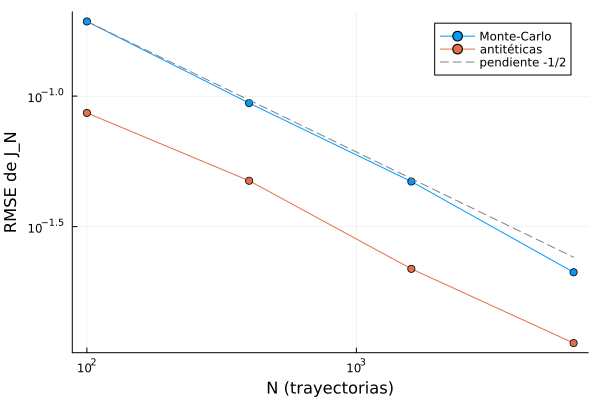

In [29]:
pendiente(x, y) = (lx = log.(x); ly = log.(y); sum((lx .- mean(lx)) .* (ly .- mean(ly)))/sum((lx .- mean(lx)).^2))

Random.seed!(11)
T2, h2, R = 30.0, 1/4, 200
K2 = round(Int, T2/h2)
EY = EJmc(Pim, nu, T2, h2)
Ns = [100, 400, 1600, 6400]
rmse, cobertura, rmse_at = Float64[], Float64[], Float64[]
for Ni in Ns
    est = zeros(R); est_at = zeros(R); dentro = 0
    for rep in 1:R
        Zi = randn(K2, Ni)
        Y = utilidad_mc(Pim, nu, Zi, h2)
        m, s = ic(Y)
        est[rep] = m; dentro += abs(m - EY) <= s
        Zp = Zi[:, 1:div(Ni, 2)]                                                  # N/2 pares antitéticos
        est_at[rep] = mean((utilidad_mc(Pim, nu, Zp, h2) .+ utilidad_mc(Pim, nu, -Zp, h2)) ./ 2)
    end
    push!(rmse, sqrt(mean((est .- EY).^2))); push!(cobertura, dentro/R); push!(rmse_at, sqrt(mean((est_at .- EY).^2)))
    @printf("N = %5d: RMSE = %.5f | cobertura IC95 = %.3f | RMSE antitéticas = %.5f\n", Ni, rmse[end], cobertura[end], rmse_at[end])
end
@printf("pendiente log-log del RMSE: %.3f (teórica -1/2);  reducción de varianza antitética ~ %.1f veces\n",
        pendiente(Ns, rmse), mean((rmse ./ rmse_at).^2))

plot(Ns, [rmse rmse_at], xscale=:log10, yscale=:log10, marker=:circle, label=["Monte-Carlo" "antitéticas"],
     xlabel="N (trayectorias)", ylabel="RMSE de J_N")
plot!(Ns, rmse[1] .* sqrt.(Ns[1] ./ Ns), ls=:dash, color=:gray, label="pendiente -1/2")

## 6. Figura de la presentación

Arriba: mediana y banda 10%–90% del capital para Merton, "solo banco" y Kelly, todos con $C=\nu X$ y en los mismos escenarios. Abajo: convergencia de $\hat J_N$ (pares antitéticos) al valor exacto $V(x_0)$, con su IC al 95%. Se guarda como `mc_merton.pdf`, el archivo que usa la slide.

J_N = 15.6263 +- 0.0069   vs   V(x0) = 15.6256
reducción de varianza por antitéticas: 8.4 veces


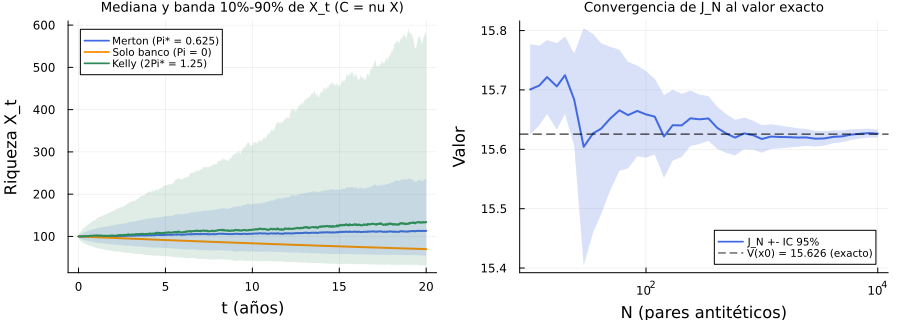

In [31]:
Random.seed!(50)
let
    # (a) trayectorias con el esquema exacto, mismos escenarios para los tres controles
    Tf, hf, Nf = 20.0, 1/52, 2000
    Kf = round(Int, Tf/hf); tf = hf .* (0:Kf)
    Zf = randn(Kf, Nf)
    pa = plot(xlabel="t (años)", ylabel="Riqueza X_t", title="Mediana y banda 10%-90% de X_t (C = nu X)",
              titlefontsize=9, legend=:topleft, legendfontsize=7)
    for (nombre, Pi, col) in [("Merton (Pi* = 0.625)", Pim, :royalblue), ("Solo banco (Pi = 0)", 0.0, :darkorange),
                              ("Kelly (2Pi* = 1.25)", 2Pim, :seagreen)]
        X = simular_exacto(Pi, nu, Zf, hf)
        q = [quantile(X[k, :], [0.1, 0.5, 0.9]) for k in 1:Kf+1]
        med = getindex.(q, 2)
        plot!(pa, tf, med, ribbon=(med .- getindex.(q, 1), getindex.(q, 3) .- med),
              fillalpha=0.15, color=col, lw=2, label=nombre)
    end

    # (b) convergencia de J_N con pares antitéticos (Prop. 3)
    Tb, hb, Nb = 10.0, 1/52, 10_000
    Zb = randn(round(Int, Tb/hb), Nb)
    Y1 = utilidad_mc(Pim, nu, Zb, hb); Y2 = utilidad_mc(Pim, nu, -Zb, hb)
    Yp = (Y1 .+ Y2) ./ 2
    Ns = unique(round.(Int, exp10.(range(1, log10(Nb), length=40))))
    m = [mean(Yp[1:n]) for n in Ns]; s = [1.96*std(Yp[1:n])/sqrt(n) for n in Ns]
    pb = plot(Ns, m, ribbon=s, fillalpha=0.2, lw=2, color=:royalblue, xscale=:log10, label="J_N +- IC 95%",
              xlabel="N (pares antitéticos)", ylabel="Valor", title="Convergencia de J_N al valor exacto",
              titlefontsize=9, legendfontsize=7, legend=:bottomright)
    hline!(pb, [V(par.x0)], ls=:dash, color=:black, label=@sprintf("V(x0) = %.3f (exacto)", V(par.x0)))

    @printf("J_N = %.4f +- %.4f   vs   V(x0) = %.4f\n", m[end], s[end], V(par.x0))
    @printf("reducción de varianza por antitéticas: %.1f veces\n", (var(Y1)/2)/var(Yp))
    #fig = plot(pa, pb, layout=(2, 1), size=(450, 560))
    fig = plot(pa, pb, layout=(1, 2), size=(900, 320), left_margin=4Plots.mm, bottom_margin=4Plots.mm)
    savefig(fig, "mc_merton.pdf")
    fig
end

## 7. Conclusiones y pendientes

**Conclusiones.**
1. Con estrategias proporcionales el capital es lognormal, así que la simulación log-Euler es **exacta** y nunca hay quiebra.
2. Con el valor de continuación exacto, el estimador $\hat J_N$ solo tiene el sesgo de la cuadratura ($O(h^2)$, conocido); el error estadístico decae como $N^{-1/2}$, los intervalos tienen la cobertura esperada y las variables antitéticas reducen la varianza.
3. **Monte-Carlo confirma la teoría:** $\hat J_N$ converge al valor exacto $V(x)$, y el control de Merton $(\Pi^*,\nu)$ es mejor que todos los demás controles simulados.

**Pendientes** (como en la presentación):
* filtro de Kalman para estimar los parámetros de la dinámica ($\mu$, $\sigma$);
* resolución numérica de la HJB y comparación con $\Pi^*$ y $\nu$;
* controles admisibles restringidos (por ejemplo, Markovianos) y horizonte finito $T$ o tiempo de parada $\tau$;
* extensiones: varios activos, $\mu(t)$ y $\sigma(t)$ no autónomos, cambios de $\Pi_t$ acotados, costos de transacción, y variar los parámetros para comparar enfoques.